# Khula! Farm-Gate Price Risk for Production Finance

| | |
|---|---|
| **Student name** | Gopolang Mmutlwane |
| **Module** | Data Science in Finance |
| **Assessment** | Summative Submission 3 (SS3), Part A |
| **Case company** | Khula! (South African agritech) |
| **AI Conversation Link** | https://claude.ai/share/61e93de4-793b-4396-a256-ddcdc45c32cb |

## Introduction

**Business question**
Using StatsSA's monthly Producer Price Index (January 2012 – August 2026), what six-month percentage fall in farm-gate prices marks the worst 25%, 20%, 10% and 5% of six-month periods for vegetables (tomatoes, onions, potatoes), cereal grains (maize, wheat) and live animals (cattle, sheep, pigs, poultry)? Are the differences between the groups large enough to justify Khula!'s funders applying different repayment buffers at each level the data can reliably test?

*Definition:* the fall at the Xth percentile is the six-month percentage fall that is reached or exceeded in X% of six-month periods (for example, the 10th percentile is reached or exceeded in one period in ten). The criterion used to judge "justify" is set out in Section 6.

**Why it matters to Khula!**
Khula! offers farmers a single application to several funders for production finance (Khula!, 2025). This analysis assumes that such finance is repaid from the proceeds when the crops or animals are sold. Under that assumption, a fall in farm-gate prices between financing and sale puts repayment at risk. This notebook measures how large and how frequent such falls have been for three product groups.

*Reference:* Khula! (2025) *Khula | Smart Farming*. Available at: https://www.khula.co.za/ (Accessed: 9 October 2026).

**Data**
- Source: Statistics South Africa (StatsSA), Producer Price Index, statistical release P0142.1, *PPI Historicals Elementary Indices*, August 2026 release.
- Link: [StatsSA Time series data](https://www.statssa.gov.za/?page_id=1847) → *Time series data – Excel and ASCII format* → *P0142.1: PPI Historicals Elementary Indices (202608)*, Excel version (accessed 7 October 2026). Direct file: [P0142.1 PPI Historicals Elementary Indices (202608).zip](https://www.statssa.gov.za/timeseriesdata/Excel/P0142.1%20PPI%20Historicals%20Elementary%20Indices%20(202608).zip)

## 1. Load the data
The raw StatsSA file has one row per product and one column per month (`M201201` = January 2012).

In [1]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Source: Statistics South Africa (2026b), PPI P0142.1 "PPI Historicals Elementary Indices (202608)".
# The file is the unchanged StatsSA download, saved under a descriptive file name.
RAW_FILE = "../data/statssa_ppi_p0142_1_elementary_indices_202608.xlsx"

raw = pd.read_excel(RAW_FILE, dtype={"cpcProdCode": str}).dropna(how="all")
raw.head()

,cpcProdCode,Table,DESCR,SIC,cpcProdDesc,WEIGHTS_2026,M201201,M201202,M201203,M201204,...,M202511,M202512,M202601,M202602,M202603,M202604,M202605,M202606,M202607,M202608
0,211110001,Final manufactured goods,Meat and meat products,3011,Beef carcasses,0.695140,47.1,44.1,39.9,38.8,...,121.6,123.6,109.1,103.1,102.7,101.2,101.8,105.9,117.7,110.4
1,211130001,Final manufactured goods,Meat and meat products,3011,Pork carcasses,0.158963,59.2,57.8,54.8,53.8,...,125.3,133.0,126.3,129.9,130.0,120.6,110.1,96.8,89.4,88.6
2,211150001,Final manufactured goods,Meat and meat products,3011,Lamb carcasses,0.114958,60.1,60.5,58.6,58.9,...,128.9,137.1,125.7,122.1,118.4,117.8,130.3,132.0,132.9,132.4
3,211210001,Final manufactured goods,Meat and meat products,3011,Chicken - fresh or chilled,0.107048,49.1,47.5,46.4,48.9,...,96.1,96.6,96.7,99.9,96.5,96.8,97.5,97.6,97.3,96.1
4,211410001,Final manufactured goods,Meat and meat products,3011,Frozen chicken,0.657579,46.3,44.4,45.0,44.6,...,104.2,104.8,104.0,104.5,104.8,104.6,103.5,101.1,101.6,100.5


In [3]:
month_cols = [c for c in raw.columns if str(c).startswith("M20")]

print("Rows (products):", len(raw))
print("Month columns:", len(month_cols), "from", month_cols[0], "to", month_cols[-1])
print("Other columns:", [c for c in raw.columns if c not in month_cols])
print("\nProducts per table:")
print(raw["Table"].value_counts())

Rows (products): 277
Month columns: 176 from M201201 to M202608
Other columns: ['cpcProdCode', 'Table', 'DESCR', 'SIC', 'cpcProdDesc', 'WEIGHTS_2026']

Products per table:
Table
Final manufactured goods             190
Intermediate manufactured goods       33
Agriculture, forestry and fishing     30
Mining                                21
Electricity and water                  3
Name: count, dtype: int64


The file holds 277 product-level price indices, one per row, with 176 monthly columns from January 2012 to August 2026. Agriculture, forestry and fishing contributes 30 of them, which is the table this analysis draws on.

In [4]:
print("Sheets in the workbook:", pd.ExcelFile(RAW_FILE).sheet_names)
print("\nSum of WEIGHTS_2026 within each table:")
print(raw.groupby("Table")["WEIGHTS_2026"].sum().round(2).to_string())

Sheets in the workbook: ['Sheet1']

Sum of WEIGHTS_2026 within each table:
Table
Agriculture, forestry and fishing    100.0
Electricity and water                100.0
Final manufactured goods             100.0
Intermediate manufactured goods      100.0
Mining                               100.0


**Interpretation:** The workbook has a single sheet with no notes or data dictionary, so the column meanings must come from StatsSA's methods report. The weights sum to 100 within each industry table, so `WEIGHTS_2026` is each product's percentage share of its own table, not of the whole PPI.

## 2. Base-period test
If the indices use December 2023 = 100, every series should equal exactly 100 in December 2023 (column `M202312`).

In [5]:
dec23 = raw["M202312"]
print("Series with a Dec 2023 value:", dec23.notna().sum())
print("Series equal to 100.0 in Dec 2023:", (dec23.round(1) == 100.0).sum())
print("Min / max in Dec 2023:", dec23.min(), "/", dec23.max())

Series with a Dec 2023 value: 277
Series equal to 100.0 in Dec 2023: 277
Min / max in Dec 2023: 100 / 100


**Interpretation:** 

All 277 series equal exactly 100 in December 2023, so every product in the file is on the same base. This matches StatsSA's methods report: "All indices were re-referenced to 100 in December 2023" (Statistics South Africa, 2026a, p. 11). Index values can therefore be compared across products. Without this check, a mix of old and new bases could make price changes look larger or smaller than they were.

## 3. Select agricultural products and reshape
Forestry and fishing are excluded because the business question concerns crops and livestock. The file is "wide" (one column per month), so it is reshaped to "long" (one row per product per month) with a proper date column.

In [6]:
agri = raw[(raw["Table"] == "Agriculture, forestry and fishing")
           & (~raw["DESCR"].isin(["Forestry", "Fishing"]))].copy()
print("Agricultural products:", len(agri))

long = agri.melt(
    id_vars=["cpcProdCode", "DESCR", "cpcProdDesc", "WEIGHTS_2026"],
    value_vars=month_cols, var_name="month", value_name="index")
long["date"] = pd.to_datetime(long["month"].str[1:], format="%Y%m")
long = long.drop(columns="month").rename(
    columns={"DESCR": "subgroup", "cpcProdDesc": "product", "WEIGHTS_2026": "weight_2026"})

# Coverage per product: first month, last month, number of months with data
coverage = (long.dropna(subset=["index"])
            .groupby("product")
            .agg(first=("date", "min"), last=("date", "max"), months=("index", "count")))
print(coverage.sort_values("months").to_string())

Agricultural products: 24
                             first       last  months
product                                              
Carrots                 2023-12-01 2026-08-01      33
Cabbage and red cabbage 2023-12-01 2026-08-01      33
Pumpkins                2023-12-01 2026-08-01      33
Soybeans                2020-12-01 2026-08-01      69
Pears                   2015-01-01 2026-08-01     140
Grapes                  2013-12-01 2026-08-01     153
Lemons                  2013-12-01 2026-08-01     153
Apples                  2012-01-01 2026-08-01     176
Cattle                  2012-01-01 2026-08-01     176
Eggs                    2012-01-01 2026-08-01     176
Onions                  2012-01-01 2026-08-01     176
Maize                   2012-01-01 2026-08-01     176
Oranges                 2012-01-01 2026-08-01     176
Pigs                    2012-01-01 2026-08-01     176
Potatoes                2012-01-01 2026-08-01     176
Bananas                 2012-01-01 2026-08-01     176
Po

There are 24 agricultural products, but they do not all cover the same period. Seventeen have the full 176 months. Carrots, cabbage and pumpkins only start in December 2023 (33 months), soybeans in December 2020, pears in January 2015, and grapes and lemons in December 2013. The late starters have no values before their first month; these are not gaps inside a series. A 2012–2026 comparison therefore has to use only the full-history products, otherwise each group would be measured over different periods.

## 4. Analysis set
Products are selected by a rule, not by how volatile they are. Three of StatsSA's agricultural subgroups are used, and within each, every product of the right type that has the full 176-month history:
- **Live animals:** all four products (cattle, sheep, pigs, poultry).
- **Vegetables:** the vegetables in *Fruit and vegetables* with full history (tomatoes, onions, potatoes). Cabbage, carrots and pumpkins start only in December 2023.
- **Cereal grains:** the cereals in *Cereals and other crops* (maize, wheat). Sunflower seed (an oilseed) and sugar cane are not cereals.

Fruit, milk and eggs, and wool are outside the scope of this question. The table below shows the subgroup and history of every agricultural product.

In [7]:
selection = (agri.assign(full_history=agri[month_cols].notna().all(axis=1))
                 [["DESCR", "cpcProdDesc", "full_history"]]
                 .rename(columns={"DESCR": "StatsSA subgroup", "cpcProdDesc": "product"}))
print(selection.to_string(index=False))

                  StatsSA subgroup                 product  full_history
           Cereals and other crops                   Wheat          True
           Cereals and other crops                   Maize          True
           Cereals and other crops                Soybeans         False
           Cereals and other crops          Sunflower seed          True
           Cereals and other crops              Sugar cane          True
Fruit and vegetables (Agriculture) Cabbage and red cabbage         False
Fruit and vegetables (Agriculture)                Tomatoes          True
Fruit and vegetables (Agriculture)                Pumpkins         False
Fruit and vegetables (Agriculture)                 Carrots         False
Fruit and vegetables (Agriculture)                  Onions          True
Fruit and vegetables (Agriculture)                 Bananas          True
Fruit and vegetables (Agriculture)                  Lemons         False
Fruit and vegetables (Agriculture)                 

In [8]:
GROUPS = {
    "Tomatoes": "Vegetables", "Onions": "Vegetables", "Potatoes": "Vegetables",
    "Maize": "Cereal grains", "Wheat": "Cereal grains",
    "Cattle": "Live animals", "Sheep": "Live animals",
    "Pigs": "Live animals", "Poultry": "Live animals",
}
long["group"] = long["product"].map(GROUPS)

full_history = coverage.index[coverage["months"] == len(month_cols)]
print("Selected products with full history:",
      [p for p in GROUPS if p in full_history])

weights = agri.set_index("cpcProdDesc")["WEIGHTS_2026"]
w = weights / weights.sum() * 100
print(f"\nShare of agricultural PPI weight covered by the nine products: {w[list(GROUPS)].sum():.1f}%")
print("Share by group (%):")
print(pd.Series(GROUPS).to_frame("group").join(w.rename("weight_share")).groupby("group")["weight_share"].sum().round(1).to_string())


Selected products with full history: ['Tomatoes', 'Onions', 'Potatoes', 'Maize', 'Wheat', 'Cattle', 'Sheep', 'Pigs', 'Poultry']

Share of agricultural PPI weight covered by the nine products: 57.5%
Share by group (%):
group
Cereal grains    17.5
Live animals     31.1
Vegetables        8.9


All nine selected products have the full history. Using StatsSA's 2026 weights, the nine products account for 57.5% of the agricultural index weight (excluding forestry and fishing): live animals 31.1%, cereal grains 17.5% and vegetables 8.9%. Poultry, maize and cattle carry the most weight. Results for vegetables therefore describe a small part of the agricultural index, and products such as fruit, milk and eggs are not covered.

## 5. Why percentage changes, not index levels
An index level such as 84.5 only says how a price compares with December 2023. Over 14 years, index levels can drift upward with general price increases, in which case their standard deviation would mix that long-term drift with short-term swings. A funder cares about how much a farmer's selling price can **change** between financing and sale. The analysis therefore uses the **six-month percentage change** in each product's index (`chg_6m`). One-month changes (`chg_1m`) are also calculated. The table below compares the spread of levels and changes to test whether this choice matters.

In [9]:
an = long[long["group"].notna()].sort_values(["product", "date"]).copy()
by_product = an.groupby("product")["index"]
an["chg_1m"] = by_product.pct_change(1, fill_method=None) * 100
an["chg_6m"] = by_product.pct_change(6, fill_method=None) * 100

print("Rows in analysis set:", an.shape)
print("\nSix-month changes available per product:")
print(an.groupby("product")["chg_6m"].count().to_string())
print("\nExample (tomatoes):")
print(an.loc[an["product"] == "Tomatoes", ["date", "index", "chg_6m"]].iloc[4:9].round({"index": 1, "chg_6m": 1}).to_string(index=False))

Rows in analysis set: (1584, 9)

Six-month changes available per product:
product
Cattle      170
Maize       170
Onions      170
Pigs        170
Potatoes    170
Poultry     170
Sheep       170
Tomatoes    170
Wheat       170

Example (tomatoes):
      date  index  chg_6m
2012-05-01   40.2     NaN
2012-06-01   44.1     NaN
2012-07-01   39.3    13.6
2012-08-01   36.6     3.1
2012-09-01   51.0    12.8


 The analysis set has 1,584 rows (9 products × 176 months). Each product has 170 six-month changes, because the first six months have no earlier value to compare with. For example, the tomato index of 39.3 in July 2012 is 13.6% higher than in January 2012.

In [10]:
level_vs_change = (an.groupby(["group", "product"])
                     .agg(level_sd=("index", "std"),
                          chg_1m_sd=("chg_1m", "std"),
                          chg_1m_median_abs=("chg_1m", lambda x: x.abs().median()),
                          chg_6m_sd=("chg_6m", "std"))
                     .round(1))
print(level_vs_change.to_string())

                        level_sd  chg_1m_sd  chg_1m_median_abs  chg_6m_sd
group         product                                                    
Cereal grains Maize         23.8        6.9                4.9       20.3
              Wheat         19.9        4.6                2.5       11.5
Live animals  Cattle        21.7        3.7                1.7       10.5
              Pigs          19.6        5.3                2.6       16.3
              Poultry       19.9        5.6                3.3       13.4
              Sheep         24.9        3.7                2.6        9.5
Vegetables    Onions        38.1       12.3                7.0       36.0
              Potatoes      20.9       12.0                6.9       32.3
              Tomatoes      24.8       19.0               13.3       30.1


Measured on index levels, the products look similar: most standard deviations are between 20 and 25, and tomatoes (24.8) look no riskier than maize (23.8). Index levels moved a long way over the period: the tomato index was about 40 in mid-2012 (example above) and every series equals 100 in December 2023 (Section 2). The level SD therefore largely reflects this long-term movement rather than short-term swings. Measured on changes, the products separate clearly. The SD of monthly changes is 19.0% for tomatoes and 6.9% for maize; this measures how widely monthly changes are spread around their average, not the size of a typical move. The typical (median absolute) monthly move is 13.3% for tomatoes and 4.9% for maize, and 1.7% for cattle. Over six months, the SD is 30–36% for vegetables and 9–20% for grains and livestock. Statistics on levels would hide the risk this question is about, so `chg_6m` is the column analysed.

## 6. Descriptive statistics of six-month price changes
All statistics below use `chg_6m`. Results are shown per **group** (all months of all products in the group pooled) and per **product**. Because the six-month windows overlap (each month starts a new window), neighbouring values are not independent: the roughly 170 values per product contain only about 28 separate half-years.

**Criterion for "justify".** Two parts are tested for each pair of groups:
- **(a) Ordering:** one group's fall is larger at all four levels (25th, 20th, 10th and 5th percentiles). If the falls cross between levels, the ranking depends on the funder's chosen level, and the data does not justify different buffers for that pair.
- **(b) Robustness:** at each level, the ordering also holds at 3-, 6- and 12-month horizons, and the ranges of that level across non-overlapping windows do not overlap. This is tested only at levels where every group has at least 5 non-overlapping six-month periods in its tail, which Section 7 shows are the 25th, 20th and 10th percentiles. The 5th percentile is reported as indicative only.

Different buffers for a pair are justified if (a) holds and (b) holds at every tested level. If (b) passes at some tested levels and fails at others, the result depends on the funder's chosen level and is treated as not justified. Levels beyond the 5th percentile are not reported, because the data contains too few non-overlapping six-month periods to estimate them. Part (a) is tested in Section 6.5 and part (b) in Section 7.

### 6.1 Mean

In [11]:
d = an.dropna(subset=["chg_6m"])

print("Mean six-month change (%) by group:")
print(d.groupby("group")["chg_6m"].mean().round(1).to_string())
print("\nMean six-month change (%) by product:")
print(d.groupby(["group", "product"])["chg_6m"].mean().round(1).to_string())

Mean six-month change (%) by group:
group
Cereal grains    3.5
Live animals     3.6
Vegetables       8.7

Mean six-month change (%) by product:
group          product 
Cereal grains  Maize        3.9
               Wheat        3.1
Live animals   Cattle       3.5
               Pigs         4.4
               Poultry      3.1
               Sheep        3.5
Vegetables     Onions      10.8
               Potatoes     7.4
               Tomatoes     8.0


**Interpretation:**

On average, prices rose in every group: about 3.5% per six months for cereal grains and live animals, and 8.7% for vegetables. These are **nominal** changes. The index is in current rand, so part of each rise reflects general inflation rather than a real gain for farmers, and this notebook does not measure how much. A positive average also does not mean low risk: a funder is hurt by the periods when prices fall, not by the average period, so the mean cannot answer the business question on its own.

### 6.2 Median

In [12]:
print("Median six-month change (%) by group:")
print(d.groupby("group")["chg_6m"].median().round(1).to_string())
print("\nMean vs median by product:")
print(d.groupby(["group", "product"])["chg_6m"].agg(mean="mean", median="median").round(1).to_string())

Median six-month change (%) by group:
group
Cereal grains    3.1
Live animals     2.6
Vegetables       4.2

Mean vs median by product:
                        mean  median
group         product               
Cereal grains Maize      3.9     4.3
              Wheat      3.1     2.4
Live animals  Cattle     3.5     2.3
              Pigs       4.4     2.6
              Poultry    3.1     2.8
              Sheep      3.5     3.0
Vegetables    Onions    10.8     4.2
              Potatoes   7.4     2.3
              Tomatoes   8.0     5.7


**Interpretation:** 

For vegetables the mean (8.7%) is about double the median (4.2%). The gap is largest for onions (10.8% vs 4.2%) and potatoes (7.4% vs 2.3%). A small number of very large price rises pull the mean up, so vegetable price changes are **right-skewed**: a typical six-month period brings a much smaller rise than the mean suggests. At group level, cereal grains (3.5% vs 3.1%) and live animals (3.6% vs 2.6%) have means within about 1 percentage point of their medians. Within live animals, pigs (4.4% vs 2.6%) and cattle (3.5% vs 2.3%) also lean to the right, so some products are skewed even where their group is not.

### 6.3 Standard deviation

In [13]:
print("Standard deviation of six-month changes (%) by group:")
print(d.groupby("group")["chg_6m"].std().round(1).to_string())
print("\nBy product:")
print(d.groupby(["group", "product"])["chg_6m"].std().round(1).to_string())

Standard deviation of six-month changes (%) by group:
group
Cereal grains    16.5
Live animals     12.7
Vegetables       32.9

By product:
group          product 
Cereal grains  Maize       20.3
               Wheat       11.5
Live animals   Cattle      10.5
               Pigs        16.3
               Poultry     13.4
               Sheep        9.5
Vegetables     Onions      36.0
               Potatoes    32.3
               Tomatoes    30.1


**Interpretation:**

Vegetables (32.9%) have about 2.6 times the spread of live animals (12.7%) and twice that of cereal grains (16.5%). Within groups, maize (20.3%) is much more spread than wheat (11.5%), and pigs (16.3%) more than sheep (9.5%), so the groups are not uniform inside. The SD counts large rises as well as large falls, and Section 6.2 showed that vegetables have a long tail of rises. A high SD therefore does not by itself show greater **downside** risk. The downside measures (P10, P5, the minimum and the share of periods with falls of 10% or 20% or more) follow in Section 6.5.

### 6.4 Outliers
Outliers are identified per product with the IQR rule: a six-month change is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Fences are set per product because Section 6.3 showed that products differ widely in how much they normally move (SD from 9.5% for sheep to 36.0% for onions). One fence for all products would flag ordinary vegetable swings and miss unusual livestock ones. Outliers are investigated, not deleted, because they may be real market events.

In [14]:
q = d.groupby("product")["chg_6m"].quantile([0.25, 0.75]).unstack()
q.columns = ["q1", "q3"]
q["iqr"] = q["q3"] - q["q1"]
q["lower"] = q["q1"] - 1.5 * q["iqr"]
q["upper"] = q["q3"] + 1.5 * q["iqr"]

dq = d.join(q[["lower", "upper"]], on="product")
dq["outlier"] = (dq["chg_6m"] < dq["lower"]) | (dq["chg_6m"] > dq["upper"])
dq["low_outlier"] = dq["chg_6m"] < dq["lower"]

summary = (dq.groupby(["group", "product"])
             .agg(lower_fence=("lower", "first"), upper_fence=("upper", "first"),
                  outliers=("outlier", "sum"), low_outliers=("low_outlier", "sum"))
             .round(1))
print(summary.to_string())
print("\nTotal outliers:", dq["outlier"].sum(), "of", len(dq))
print("Of which falls:", dq["low_outlier"].sum())

                        lower_fence  upper_fence  outliers  low_outliers
group         product                                                   
Cereal grains Maize           -48.4         56.8         2             1
              Wheat           -25.6         30.1         3             0
Live animals  Cattle          -21.0         27.7         5             0
              Pigs            -34.2         42.7         5             1
              Poultry         -33.0         38.2         1             0
              Sheep           -20.8         27.3         1             0
Vegetables    Onions          -86.5        107.2         1             0
              Potatoes        -83.1         90.6         4             0
              Tomatoes        -76.0         88.0         0             0

Total outliers: 22 of 1530
Of which falls: 2


In [15]:
outliers = dq.loc[dq["outlier"], ["product", "date", "index", "chg_6m"]]
outliers = outliers.sort_values("chg_6m", key=abs, ascending=False)
print(outliers.round({"index": 1, "chg_6m": 1}).to_string(index=False))

 product       date  index  chg_6m
Potatoes 2016-02-01   70.8   132.9
Potatoes 2016-03-01   78.7   131.5
  Onions 2016-04-01  110.5   112.9
Potatoes 2016-04-01   68.7   101.5
Potatoes 2016-01-01   61.0    92.4
   Maize 2016-01-01  103.7    60.0
    Pigs 2020-12-01   84.9    50.8
   Maize 2017-06-01   42.3   -50.5
    Pigs 2020-11-01   82.0    49.6
    Pigs 2018-11-01   72.9    46.4
    Pigs 2020-10-01   79.0    44.4
 Poultry 2025-07-01   94.6    41.6
   Wheat 2022-05-01  136.7    34.5
  Cattle 2025-06-01  139.9    34.4
    Pigs 2018-05-01   49.8   -34.2
   Wheat 2012-10-01   62.1    33.8
   Wheat 2022-06-01  137.1    31.3
  Cattle 2025-08-01  128.3    29.9
   Sheep 2017-08-01   95.6    29.2
  Cattle 2025-05-01  122.5    28.5
  Cattle 2025-07-01  128.9    28.4
  Cattle 2017-06-01   91.3    28.1


In [16]:
def show(product, start, end):
    s = an.loc[(an["product"] == product) & an["date"].between(start, end),
               ["date", "index", "chg_1m", "chg_6m"]]
    s = s.assign(date=s["date"].dt.strftime("%Y-%m"))
    print(product)
    print(s.round({"index": 1, "chg_1m": 1, "chg_6m": 1}).to_string(index=False))
    print()

show("Potatoes", "2015-06", "2016-06")
show("Maize", "2016-10", "2017-08")
show("Pigs", "2017-10", "2018-07")

Potatoes
   date  index  chg_1m  chg_6m
2015-06   32.4    -4.4   -18.8
2015-07   31.7    -2.2   -11.0
2015-08   30.4    -4.1   -12.1
2015-09   34.0    11.8    -7.1
2015-10   34.1     0.3    -8.1
2015-11   37.1     8.8     9.4
2015-12   48.9    31.8    50.9
2016-01   61.0    24.7    92.4
2016-02   70.8    16.1   132.9
2016-03   78.7    11.2   131.5
2016-04   68.7   -12.7   101.5
2016-05   56.9   -17.2    53.4
2016-06   55.4    -2.6    13.3

Maize
   date  index  chg_1m  chg_6m
2016-10   78.4    -6.6   -11.7
2016-11   81.7     4.2   -13.5
2016-12   85.5     4.7   -13.6
2017-01   78.4    -8.3   -13.7
2017-02   68.9   -12.1   -18.3
2017-03   51.8   -24.8   -38.3
2017-04   48.0    -7.3   -38.8
2017-05   44.8    -6.7   -45.2
2017-06   42.3    -5.6   -50.5
2017-07   44.4     5.0   -43.4
2017-08   44.3    -0.2   -35.7

Pigs
   date  index  chg_1m  chg_6m
2017-10   74.8     3.7     9.8
2017-11   75.7     1.2    11.7
2017-12   77.4     2.2    13.3
2018-01   74.5    -3.7     8.9
2018-02   70.3   

**Interpretation:**

22 of the 1,530 six-month changes (1.4%) are outliers, and 20 of them are price **rises**. Only two are falls: maize −50.5% (June 2017) and pigs −34.2% (May 2018). Tomatoes have none, because their normal swings are so wide that the fences stretch from −76% to +88%.

Consecutive outliers alone do not show a real event, since one unusual month appears in six overlapping windows. The monthly index above gives better evidence. The potato index rose from 30.4 (August 2015) to 78.7 (March 2016), with rises of 11–32% in each of four consecutive months, before falling back to 55.4 by June 2016. The maize index fell in every month from 85.5 (December 2016) to 42.3 (June 2017). The pig index dropped 21.7% in April 2018 and stayed between 49.8 and 58.0 over the following three months instead of returning to its earlier level of about 75. These are sustained movements over several months, not single-month spikes, which is consistent with real price changes rather than data-entry errors. The outliers are therefore kept. Their causes are not identified here, because the data alone cannot show them.

For a funder, a price spike helps repayment. The risk lies in falls, and extreme falls are rare, so a bad case is better measured with a low percentile (Section 6.5) than with the single worst value.

### 6.5 Distribution and ranges
This section shows the full shape of six-month changes per group: the range (minimum to maximum), the quartiles, and the bad end of the distribution that the business question asks about. The bad end is described at four levels, the 25th, 20th, 10th and 5th percentiles (P25, P20, P10, P5), where the fall at the Xth percentile is reached or exceeded in X% of six-month periods. Which level matters is the funder's choice, because thresholds must reflect capacity, cost and risk appetite (Topic 5). The tables below report all four levels, and the final code cell in this section tests part (a) of the criterion: whether one group's fall is larger at every level. P5 is reported as indicative only, because Section 7 shows it rests on fewer than 5 non-overlapping six-month periods for vegetables and cereal grains.

In [17]:
ORDER = ["Vegetables", "Cereal grains", "Live animals"]

def ranges(x):
    return pd.Series({
        "min": x.min(), "p5": x.quantile(0.05), "p10": x.quantile(0.10),
        "q1": x.quantile(0.25), "median": x.median(), "q3": x.quantile(0.75),
        "max": x.max(), "range": x.max() - x.min(),
        "iqr": x.quantile(0.75) - x.quantile(0.25),
    })

print("Ranges of six-month changes (%) by group:")
print(d.groupby("group")["chg_6m"].apply(ranges).unstack().loc[ORDER].round(1).to_string())
print("\nBy product:")
print(d.groupby(["group", "product"])["chg_6m"].apply(ranges).unstack()[["min", "p10", "median", "max"]].round(1).to_string())
print("\nSkewness by group:")
print(d.groupby("group")["chg_6m"].skew().loc[ORDER].round(2).to_string())

Ranges of six-month changes (%) by group:
                min    p5   p10    q1  median    q3    max  range   iqr
group                                                                  
Vegetables    -56.2 -37.3 -31.4 -16.5     4.2  30.0  132.9  189.0  46.5
Cereal grains -50.5 -23.4 -15.1  -6.8     3.1  13.2   60.0  110.6  20.1
Live animals  -34.2 -16.1 -11.8  -3.9     2.6  10.6   50.8   85.0  14.6

By product:
                         min   p10  median    max
group         product                            
Cereal grains Maize    -50.5 -23.4     4.3   60.0
              Wheat    -21.0 -11.1     2.4   34.5
Live animals  Cattle   -17.3  -9.4     2.3   34.4
              Pigs     -34.2 -16.2     2.6   50.8
              Poultry  -32.0 -14.8     2.8   41.6
              Sheep    -17.6  -7.5     3.0   29.2
Vegetables    Onions   -56.2 -33.2     4.2  112.9
              Potatoes -40.5 -28.4     2.3  132.9
              Tomatoes -55.4 -28.9     5.7   79.4

Skewness by group:
group
Vegetable

In [18]:
falls = (d.groupby("group")["chg_6m"]
           .agg(any_fall=lambda x: (x < 0).mean() * 100,
                fall_10pct_or_more=lambda x: (x <= -10).mean() * 100,
                fall_20pct_or_more=lambda x: (x <= -20).mean() * 100)
           .loc[ORDER].round(1))
print("Share of six-month periods with a price fall (%):")
print(falls.to_string())

Share of six-month periods with a price fall (%):
               any_fall  fall_10pct_or_more  fall_20pct_or_more
group                                                          
Vegetables         42.9                30.8                19.0
Cereal grains      38.2                19.1                 6.8
Live animals       38.2                12.2                 2.5


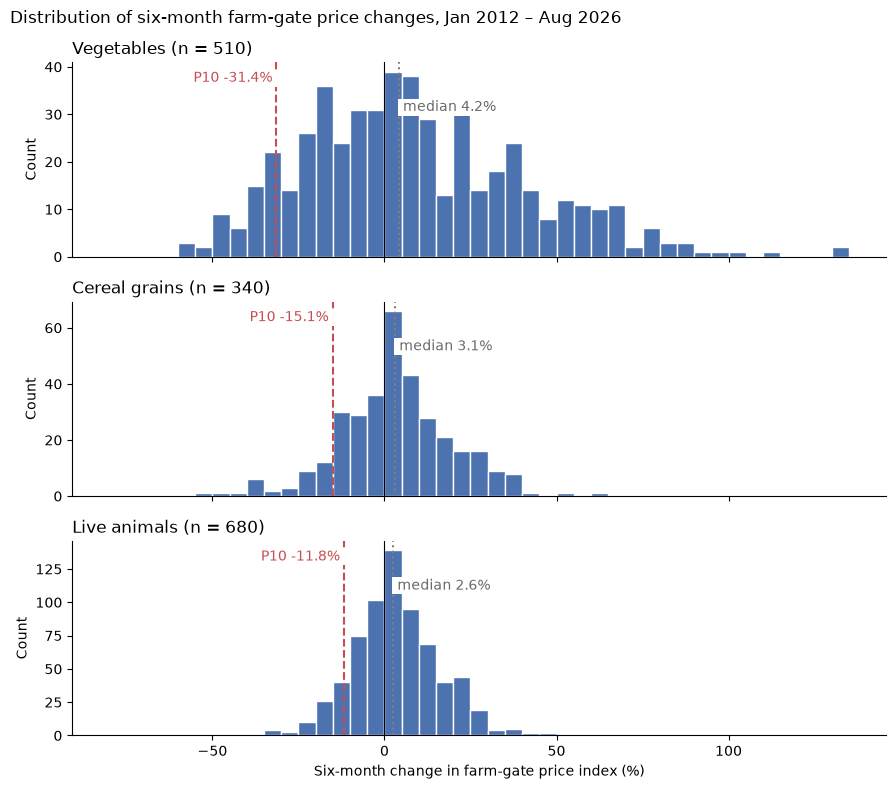

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
bins = np.arange(-80, 140, 5)

for ax, g in zip(axes, ORDER):
    x = d.loc[d["group"] == g, "chg_6m"]
    p10, med = x.quantile(0.10), x.median()
    ax.hist(x, bins=bins, color="#4C72B0", edgecolor="white")
    ax.axvline(0, color="black", lw=0.8)
    ax.axvline(p10, color="#C44E52", ls="--", lw=1.5)
    ax.axvline(med, color="grey", ls=":", lw=1.5)
    top = ax.get_ylim()[1]
    ax.text(p10, top * 0.9, f"P10 {p10:.1f}% ", color="#C44E52", ha="right",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.text(med, top * 0.75, f" median {med:.1f}%", color="dimgrey",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_title(f"{g} (n = {len(x)})", loc="left")
    ax.set_ylabel("Count")
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("Six-month change in farm-gate price index (%)")
fig.suptitle("Distribution of six-month farm-gate price changes, Jan 2012 – Aug 2026", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Interpretation:**

In one in ten six-month periods (the P10), vegetable prices fell by 31.4% or more, compared with 15.1% or more for cereal grains and 11.8% or more for live animals. Vegetables also have by far the widest spread: a range of 189 percentage points and an IQR of 46.5, roughly three times that of live animals (14.6).

Prices fell in roughly 40% of six-month periods in every group (38.2–42.9%), so falls themselves are common. What differs is their **size**: 19.0% of vegetable periods had a fall of 20% or more, against 6.8% for cereal grains and 2.5% for live animals.

The histograms confirm the right skew found in 6.2. Vegetables (skewness 0.62) have a long tail of large rises, up to +132.9%, while their falls stop at −56.2%. Cereal grains are close to symmetrical (−0.05). Within groups, maize (P10 −23.4%) is closer to the vegetables than to wheat (−11.1%), and pigs (−16.2%) and poultry (−14.8%) have worse bad cases than cattle (−9.4%) and sheep (−7.5%).

In [20]:
LEVELS = [0.25, 0.20, 0.10, 0.05]
levels = pd.DataFrame({f"P{int(p * 100)}": d.groupby("group")["chg_6m"].quantile(p)
                       for p in LEVELS}).loc[ORDER]
print("Six-month change (%) reached or exceeded at each level, by group:")
print(levels.round(1).to_string())

pairs = [("Vegetables", "Cereal grains"), ("Vegetables", "Live animals"), ("Cereal grains", "Live animals")]
check = pd.DataFrame({f"{a} vs {b}": levels.loc[a] < levels.loc[b] for a, b in pairs}).T
check["larger fall at all four levels"] = check.all(axis=1)
print("\nCriterion (a): is the first group's fall larger at each level?")
print(check.to_string())

Six-month change (%) reached or exceeded at each level, by group:
                P25   P20   P10    P5
group                                
Vegetables    -16.5 -19.2 -31.4 -37.3
Cereal grains  -6.8  -8.7 -15.1 -23.4
Live animals   -3.9  -6.5 -11.8 -16.1

Criterion (a): is the first group's fall larger at each level?
                                P25   P20   P10    P5  larger fall at all four levels
Vegetables vs Cereal grains    True  True  True  True                            True
Vegetables vs Live animals     True  True  True  True                            True
Cereal grains vs Live animals  True  True  True  True                            True


**Interpretation:**

At every level, vegetables have the largest fall, then cereal grains, then live animals. In the worst 25% of six-month periods, vegetable prices fall by 16.5% or more, against 6.8% for cereal grains and 3.9% for live animals. In the worst 5%, the falls are 37.3%, 23.4% and 16.1%. Part (a) of the criterion is therefore met for all three pairs, and the groups' falls do not cross between levels.

The gaps differ in size. Vegetables' falls are 9.7 to 16.3 percentage points larger than cereal grains' and 12.6 to 21.2 points larger than live animals'. Between cereal grains and live animals the gap is only 2.2 to 3.3 points at P25 to P10, widening to 7.3 points at P5. Part (a) only tests the ordering, so whether these gaps are large enough to count is tested by part (b) in Section 7.

## 7. Sensitivity test
This section tests part (b) of the criterion. The six-month horizon is a scenario, not a documented Khula! loan term, and overlapping windows can make results look more certain than they are.

The first cell counts the non-overlapping six-month periods in each group's tail and checks how closely products within a group move together. Every group has at least 5 non-overlapping periods at the 25th, 20th and 10th percentiles, so those levels are tested; at the 5th percentile vegetables have about 4 and cereal grains about 3, so P5 is reported as indicative only.

Two checks are then applied:
1. **Horizon:** recalculate the level over 3 and 12 months.
2. **Overlap:** six-month windows that start in neighbouring months share five months of data. Recalculate the level using only non-overlapping windows (e.g. January→July and July→January), for each of the six possible pairs of end months.

The next cells show these checks in detail at P10. The following cell applies both checks at every level and gives the result of part (b). The next cell shows how the verdict would change under a different minimum number of periods. The last two code cells repeat the bad-case table and part (b) without the 2012 values, because the agriculture PPI was only introduced in January 2013.

In [21]:
sizes = pd.DataFrame({f"ends {m}/{m + 6}": d[d["date"].dt.month.isin([m, m + 6])].groupby("group").size()
                      for m in range(1, 7)}).loc[ORDER]
print("Non-overlapping six-month changes per group, by window end months:")
print(sizes.to_string())

smallest = sizes.min(axis=1)
tail = pd.DataFrame({f"P{int(p * 100)}": smallest * p for p in LEVELS})
print("\nNon-overlapping periods in each tail (smallest set x level):")
print(tail.round(1).to_string())

testable = (tail >= 5).all()
print("\nLevel can be tested (every group has at least 5):")
print(testable.to_string())

# Products in the same group can move together, so non-overlapping periods are not fully independent
corr = {}
for g in ORDER:
    pair_corrs = []
    for m in range(1, 7):
        wide = d[(d["group"] == g) & d["date"].dt.month.isin([m, m + 6])].pivot(index="date", columns="product", values="chg_6m")
        c = wide.corr().to_numpy()
        pair_corrs.extend(c[np.triu_indices_from(c, k=1)])
    corr[g] = pd.Series(pair_corrs).agg(["min", "mean", "max"])
print("\nCorrelation between products' six-month changes within each group (all six non-overlapping sets):")
print(pd.DataFrame(corr).T.round(2).to_string())

Non-overlapping six-month changes per group, by window end months:
               ends 1/7  ends 2/8  ends 3/9  ends 4/10  ends 5/11  ends 6/12
group                                                                       
Vegetables           87        87        84         84         84         84
Cereal grains        58        58        56         56         56         56
Live animals        116       116       112        112        112        112

Non-overlapping periods in each tail (smallest set x level):
                P25   P20   P10   P5
group                               
Vegetables     21.0  16.8   8.4  4.2
Cereal grains  14.0  11.2   5.6  2.8
Live animals   28.0  22.4  11.2  5.6

Level can be tested (every group has at least 5):
P25     True
P20     True
P10     True
P5     False

Correlation between products' six-month changes within each group (all six non-overlapping sets):
                min  mean   max
Vegetables    -0.32  0.04  0.42
Cereal grains  0.04  0.28  0.53
Liv

**Interpretation:**

Each group has 56 to 116 non-overlapping six-month changes, depending on which pair of end months is used. At the 25th, 20th and 10th percentiles every group has at least 5 of these in its tail, so those levels are tested. At the 5th percentile vegetables have about 4 and cereal grains about 3, so P5 is reported as indicative only.

Non-overlapping does not mean fully independent. Products in the same group can move together: the correlation between products' six-month changes averages 0.04 for vegetables, 0.28 for cereal grains and 0.23 for live animals, with individual pairs up to 0.55. For vegetables the counts are close to independent periods, but for cereal grains and live animals they are upper bounds. This matters most for cereal grains at P10, where the count (5.6) is just above the minimum, so the P10 tests involving cereal grains are less certain than the table suggests.

In [22]:
for h in [3, 12]:
    an[f"chg_{h}m"] = by_product.pct_change(h, fill_method=None) * 100

sens = pd.DataFrame({
    f"{h} months": an.groupby("group")[f"chg_{h}m"].quantile(0.10) for h in [3, 6, 12]
}).loc[ORDER].round(1)
print("P10 change (%) by horizon:")
print(sens.to_string())

P10 change (%) by horizon:
               3 months  6 months  12 months
group                                       
Vegetables        -24.6     -31.4      -25.4
Cereal grains     -11.5     -15.1      -17.3
Live animals       -9.4     -11.8      -11.1


In [23]:
blocks = {}
for m in range(1, 7):
    sub = d[d["date"].dt.month.isin([m, m + 6])]
    blocks[f"ends {m}/{m + 6}"] = sub.groupby("group")["chg_6m"].quantile(0.10)

blocks = pd.DataFrame(blocks).loc[ORDER].round(1)
blocks["lowest"] = blocks.min(axis=1)
blocks["highest"] = blocks.max(axis=1)
print("P10 of non-overlapping six-month changes (%), by window end months:")
print(blocks.to_string())

P10 of non-overlapping six-month changes (%), by window end months:
               ends 1/7  ends 2/8  ends 3/9  ends 4/10  ends 5/11  ends 6/12  lowest  highest
group                                                                                        
Vegetables        -32.4     -28.4     -25.8      -32.6      -30.2      -31.1   -32.6    -25.8
Cereal grains     -16.0     -18.4     -11.9      -10.6      -13.6      -17.6   -18.4    -10.6
Live animals      -12.9      -9.9     -10.8      -10.6      -14.1      -12.1   -14.1     -9.9


In [24]:
p10 = pd.DataFrame({f"{h} months": an.groupby("group")[f"chg_{h}m"].quantile(0.10) for h in [3, 6, 12]}).loc[ORDER]
mean = pd.DataFrame({f"{h} months": an.groupby("group")[f"chg_{h}m"].mean() for h in [3, 6, 12]}).loc[ORDER]
print("Mean change (%) by horizon:")
print(mean.round(1).to_string())
print("\nP10 minus the mean, i.e. bad case relative to average drift (%):")
print((p10 - mean).round(1).to_string())

Mean change (%) by horizon:
               3 months  6 months  12 months
group                                       
Vegetables          5.4       8.7       10.7
Cereal grains       1.7       3.5        6.8
Live animals        1.8       3.6        7.2

P10 minus the mean, i.e. bad case relative to average drift (%):
               3 months  6 months  12 months
group                                       
Vegetables        -30.1     -40.1      -36.0
Cereal grains     -13.2     -18.5      -24.1
Live animals      -11.2     -15.4      -18.3


**Interpretation:**

At P10, vegetables have the worst bad case at every horizon and for every choice of non-overlapping windows, and their range (−25.8% to −32.6%) does not overlap with either other group. Part (b) therefore passes at P10 for vegetables against both other groups.

Cereal grains and live animals fail part (b) at P10: their non-overlapping ranges overlap (cereals −10.6% to −18.4%, live animals −9.9% to −14.1%), and for windows ending in May/November live animals come out slightly worse (−14.1% vs −13.6%).

For vegetables, the 12-month P10 (−25.4%) is milder than the 6-month one (−31.4%). There are at least three possible reasons. (1) **Nominal drift:** the index includes general price increases, and the average 12-month change is larger (10.7% vs 8.7%), which lifts every change. (2) **Seasonality:** a 12-month change compares the same calendar month in two years, so seasonal swings cancel out. (3) Some falls partly reverse within a year. The drift test above shows that after subtracting the average change, the 12-month bad case is still milder (−36.0% vs −40.1%), so drift explains part of the difference but not all of it. This notebook cannot separate reasons (2) and (3).

In [25]:
rows = []
for p in LEVELS:
    name = f"P{int(p * 100)}"
    hor = pd.DataFrame({h: an.groupby("group")[f"chg_{h}m"].quantile(p) for h in [3, 6, 12]})
    nonover = pd.DataFrame({m: d[d["date"].dt.month.isin([m, m + 6])].groupby("group")["chg_6m"].quantile(p)
                            for m in range(1, 7)})
    lo, hi = nonover.min(axis=1), nonover.max(axis=1)
    for a, b in pairs:
        horizons_ok = bool((hor.loc[a] < hor.loc[b]).all())
        ranges_ok = bool(hi[a] < lo[b])   # a's mildest value is still a larger fall than b's most severe
        rows.append({"level": name, "pair": f"{a} vs {b}",
                     "larger at 3/6/12 months": horizons_ok,
                     "non-overlapping ranges separate": ranges_ok,
                     "passes both": horizons_ok and ranges_ok})

results = pd.DataFrame(rows)
print(results.to_string(index=False))

summary = results.pivot(index="pair", columns="level", values="passes both")[["P25", "P20", "P10", "P5"]]
print("\nPasses both tests (True) or not (False):")
print(summary.to_string())

print("\nP5 by horizon (%):")
print(pd.DataFrame({f"{h} months": an.groupby("group")[f"chg_{h}m"].quantile(0.05)
                    for h in [3, 6, 12]}).loc[ORDER].round(1).to_string())

level                          pair  larger at 3/6/12 months  non-overlapping ranges separate  passes both
  P25   Vegetables vs Cereal grains                     True                             True         True
  P25    Vegetables vs Live animals                     True                             True         True
  P25 Cereal grains vs Live animals                     True                            False        False
  P20   Vegetables vs Cereal grains                     True                             True         True
  P20    Vegetables vs Live animals                     True                             True         True
  P20 Cereal grains vs Live animals                     True                             True         True
  P10   Vegetables vs Cereal grains                     True                             True         True
  P10    Vegetables vs Live animals                     True                             True         True
  P10 Cereal grains vs Live animals  

**Interpretation:**

This table gives the result of part (b) at the three tested levels (P25, P20, P10); the P5 row is indicative only.

- **Vegetables vs live animals:** passes at P25, P20 and P10 (and also at the indicative P5). Part (b) holds.
- **Vegetables vs cereal grains:** passes at P25, P20 and P10. Part (b) holds. At the indicative P5 it fails: over 12 months, the 5th-percentile fall for cereal grains (−35.7%) is larger than for vegetables (−31.3%). This rests on about 3 non-overlapping periods for cereals, so it is a warning rather than a result, but a funder planning for the rarest falls over a 12-month term should not assume grains are safer.
- **Cereal grains vs live animals:** passes at P20 but fails at P25 and P10. Part (b) gives different answers at different tested levels, so the result depends on the level and is treated as not justified. A single pass sitting between two fails also suggests the test is noisy at these sample sizes (about 56 non-overlapping periods for cereals), so the P20 pass should not be given much weight.

In [26]:
passes = results.pivot(index="pair", columns="level", values="passes both")
verdicts = {}
for minimum in [2, 3, 5, 8, 12]:
    tested = [lvl for lvl in ["P25", "P20", "P10", "P5"] if (tail[lvl] >= minimum).all()]
    label = f"min {minimum} (tests {', '.join(tested)})"
    verdicts[label] = passes[tested].all(axis=1).map({True: "justified", False: "not justified"})

print("Verdict of part (b) under different minimum numbers of non-overlapping periods:")
print(pd.DataFrame(verdicts).to_string())

Verdict of part (b) under different minimum numbers of non-overlapping periods:
                              min 2 (tests P25, P20, P10, P5) min 3 (tests P25, P20, P10) min 5 (tests P25, P20, P10) min 8 (tests P25, P20) min 12 (tests P25)
pair                                                                                                                                                           
Cereal grains vs Live animals                   not justified               not justified               not justified          not justified      not justified
Vegetables vs Cereal grains                     not justified                   justified                   justified              justified          justified
Vegetables vs Live animals                          justified                   justified                   justified              justified          justified


**Interpretation:**

The minimum of 5 non-overlapping periods is a judgement: with fewer than about 5 values beyond a percentile, the estimate is set by one or two extreme events, so moving a single event can change it. This table shows how much the verdict depends on that choice.

- **Vegetables vs live animals** is justified under every minimum.
- **Cereal grains vs live animals** is not justified under every minimum.
- **Vegetables vs cereal grains** changes only if the 5th percentile is tested, which requires accepting a level that rests on fewer than 3 non-overlapping periods for cereal grains (2.8). Under any minimum of 3 or more, it is justified.

The two-tier conclusion therefore does not depend on choosing 5 specifically. It changes only if a level resting on two or three periods is treated as reliable.

In [27]:
an13 = an[an["date"] >= "2013-01-01"].copy()
an13["chg_6m_13"] = an13.groupby("product")["index"].pct_change(6, fill_method=None) * 100
d13 = an13.dropna(subset=["chg_6m_13"])

without_2012 = pd.DataFrame({f"P{int(p * 100)}": d13.groupby("group")["chg_6m_13"].quantile(p)
                             for p in LEVELS}).loc[ORDER]
print("Six-month change (%) at each level, excluding any change that uses a 2012 value:")
print(without_2012.round(1).to_string())
print("\nDifference from the full period (percentage points):")
print((without_2012 - levels).round(1).to_string())
print("\nSix-month changes per group:", d13.groupby("group").size().loc[ORDER].to_dict())

Six-month change (%) at each level, excluding any change that uses a 2012 value:
                P25   P20   P10    P5
group                                
Vegetables    -17.3 -20.1 -32.1 -37.6
Cereal grains  -6.9  -8.8 -16.2 -23.6
Live animals   -3.0  -5.4 -10.2 -15.2

Difference from the full period (percentage points):
               P25  P20  P10   P5
group                            
Vegetables    -0.8 -0.9 -0.7 -0.3
Cereal grains -0.1 -0.1 -1.1 -0.2
Live animals   0.9  1.1  1.6  0.9

Six-month changes per group: {'Vegetables': 474, 'Cereal grains': 316, 'Live animals': 632}


**Interpretation:**

StatsSA's methods report says the PPI for agriculture, forestry and fishing was introduced in January 2013 (Statistics South Africa, 2026a, p. 1), but the file starts in January 2012, and the report does not say how the 2012 values were produced. To check whether that first year affects the result, every six-month change that uses a 2012 value is dropped, leaving 474, 316 and 632 changes per group.

The bad-case falls change by at most 1.6 percentage points (live animals at P10, from −11.8% to −10.2%), and the ordering of the groups is the same at every level. The gap between vegetables and live animals widens at every level. The gap between vegetables and cereal grains widens at P25 and P20, is unchanged to rounding at P5, and narrows slightly at P10 (from 16.3 to 15.9 percentage points). The next cell checks whether part (b) of the criterion gives the same verdict without 2012.

In [28]:
an13["chg_3m_13"] = an13.groupby("product")["index"].pct_change(3, fill_method=None) * 100
an13["chg_12m_13"] = an13.groupby("product")["index"].pct_change(12, fill_method=None) * 100
cols13 = {3: "chg_3m_13", 6: "chg_6m_13", 12: "chg_12m_13"}

sizes13 = pd.DataFrame({m: d13[d13["date"].dt.month.isin([m, m + 6])].groupby("group").size()
                        for m in range(1, 7)}).loc[ORDER]
tail13 = pd.DataFrame({f"P{int(p * 100)}": sizes13.min(axis=1) * p for p in LEVELS})
tested13 = [lvl for lvl in ["P25", "P20", "P10", "P5"] if (tail13[lvl] >= 5).all()]

rows13 = []
for p in LEVELS:
    name = f"P{int(p * 100)}"
    hor = pd.DataFrame({h: an13.groupby("group")[c].quantile(p) for h, c in cols13.items()})
    nonover = pd.DataFrame({m: d13[d13["date"].dt.month.isin([m, m + 6])].groupby("group")["chg_6m_13"].quantile(p)
                            for m in range(1, 7)})
    lo, hi = nonover.min(axis=1), nonover.max(axis=1)
    for a, b in pairs:
        rows13.append({"level": name, "pair": f"{a} vs {b}",
                       "passes both": bool((hor.loc[a] < hor.loc[b]).all()) and bool(hi[a] < lo[b])})
passes13 = pd.DataFrame(rows13).pivot(index="pair", columns="level", values="passes both")[["P25", "P20", "P10", "P5"]]

print("Non-overlapping periods in each tail, without 2012:")
print(tail13.round(1).to_string())
print("\nTested levels without 2012:", tested13)
print("\nPart (b) without 2012 (True = passes both checks):")
print(passes13.to_string())
print("\nVerdict without 2012:")
print(passes13[tested13].all(axis=1).map({True: "justified", False: "not justified"}).to_string())

Non-overlapping periods in each tail, without 2012:
                P25   P20   P10   P5
group                               
Vegetables     19.5  15.6   7.8  3.9
Cereal grains  13.0  10.4   5.2  2.6
Live animals   26.0  20.8  10.4  5.2

Tested levels without 2012: ['P25', 'P20', 'P10']

Part (b) without 2012 (True = passes both checks):
level                            P25   P20    P10     P5
pair                                                    
Cereal grains vs Live animals  False  True  False   True
Vegetables vs Cereal grains     True  True   True  False
Vegetables vs Live animals      True  True   True   True

Verdict without 2012:
pair
Cereal grains vs Live animals    not justified
Vegetables vs Cereal grains          justified
Vegetables vs Live animals           justified


**Interpretation:**

Without 2012, every group still has at least 5 non-overlapping periods at P25, P20 and P10 (cereal grains 5.2 at P10), so the same levels are tested. Part (b) gives the same verdict for all three pairs: vegetables vs cereal grains and vs live animals are justified, and cereal grains vs live animals is not. The 2012 values therefore change neither the bad-case levels by more than 1.6 percentage points nor the conclusion of the criterion.

## 8. Conclusion

In [29]:
tiers = d.assign(tier=d["group"].where(d["group"] == "Vegetables", "Cereal grains + live animals"))
TIER_ORDER = ["Vegetables", "Cereal grains + live animals"]

fall = pd.DataFrame({f"P{int(p * 100)}": tiers.groupby("tier")["chg_6m"].quantile(p)
                     for p in LEVELS}).loc[TIER_ORDER]
print("Six-month change (%) at each level, two tiers:")
print(fall.round(1).to_string())

print("\nPrice at that level as % of starting price (100% + change):")
print((100 + fall).round(1).to_string())

Six-month change (%) at each level, two tiers:
                               P25   P20   P10    P5
tier                                                
Vegetables                   -16.5 -19.2 -31.4 -37.3
Cereal grains + live animals  -4.9  -7.5 -13.3 -18.0

Price at that level as % of starting price (100% + change):
                               P25   P20   P10    P5
tier                                                
Vegetables                    83.5  80.8  68.6  62.7
Cereal grains + live animals  95.1  92.5  86.7  82.0


**Answer to the business question.**

*How large are the bad-case falls?* Over six months, vegetable prices fall by 16.5% or more in the worst 25% of periods, 19.2% or more in the worst 20%, 31.4% or more in the worst 10% and 37.3% or more in the worst 5%. For cereal grains the falls are 6.8%, 8.7%, 15.1% and 23.4%, and for live animals 3.9%, 6.5%, 11.8% and 16.1% (Section 6.5). The 5th-percentile figures are indicative, because they rest on few non-overlapping periods (Section 7).

*Do the differences justify different buffers?* Applying the criterion from Section 6:
- **Vegetables vs cereal grains and vs live animals: justified.** Vegetables have the larger fall at all four levels (part a), and the ordering holds at every horizon with separate non-overlapping ranges at each tested level, P25, P20 and P10 (part b).
- **Cereal grains vs live animals: not justified.** Cereal grains have the larger fall at all four levels (part a), but part (b) passes only at P20 and fails at P25 and P10, so the result depends on the level chosen.

The data therefore supports **two tiers** at any of the tested levels: a larger buffer for vegetables, and one shared buffer for cereal grains and live animals. This does not depend on the minimum of 5 periods used to choose the tested levels: the verdict changes only if the 5th percentile, which rests on fewer than 3 non-overlapping periods for cereal grains, is treated as reliable (Section 7).

Two warnings for funders. First, at the indicative 5th percentile over 12 months, cereal grains fall further than vegetables (−35.7% vs −31.3%), so a funder planning for the rarest falls over a 12-month term should not assume grains are safer. Second, maize's 10th-percentile fall (−23.4%) is closer to the vegetables than to wheat's (−11.1%), so maize may deserve separate review.

**Illustrative translation into a buffer.** If a farmer repays from sales and the selling price falls by the amount at a given level, the farmer receives 100% plus that change of the expected price (table above). At the 10th percentile this is 68.6% for vegetables and 86.7% for cereal grains and live animals combined. At the 25th percentile it is 83.5% and 95.1%, and at the indicative 5th percentile 62.7% and 82.0%. A funder would size repayments against these shares of expected sales income at the level matching its risk appetite. These figures are illustrative only: they ignore yields, costs, other income and the farmer's own selling price, and Khula!'s actual loan terms are not known.

**Assumptions and limitations.**
- Repayment from sale proceeds is an assumption; Khula!'s website describes production finance but not how it is repaid (Khula!, 2025).
- Farmers sell at prices that move like the national StatsSA index. The PPI covers producers sampled by StatsSA, not Khula!'s farmers.
- The index is **nominal**. The means include general inflation, so "prices rose on average" partly reflects inflation. For repaying a fixed rand loan the nominal fall is what matters, but costs also rise with inflation, so in real terms a farmer's bad case is likely to be worse than shown.
- Yields and costs are held constant; only price risk is measured.
- Six months is a scenario horizon; 3 and 12 months were checked in Section 7.
- Non-overlapping six-month periods are few (56 to 116 per group), and they are not fully independent, because products within a group move together (average correlation 0.04 for vegetables, 0.28 for cereal grains, 0.23 for live animals). The percentiles are therefore estimates, the robustness test can give different answers at neighbouring levels, and the tests involving cereal grains at P10 are less certain than the counts suggest. The 5th percentile is indicative only.
- The criterion for "justify", the four levels and the minimum of 5 non-overlapping periods for a level to be tested are judgement choices made for this analysis.
- Only nine full-history products are used (57.5% of the agricultural index weight); vegetables are 8.9% of it.

## 9. Environment

In [30]:
import sys, openpyxl, matplotlib
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)
print("openpyxl:", openpyxl.__version__)

Python: 3.14.8
pandas: 3.0.6
numpy: 2.5.3
matplotlib: 3.11.2
openpyxl: 3.1.5
